In [33]:
import os
import torch
from torch import nn
from torch import optim                      # Optimizer
import wandb                                 # Experiment Tracking
from torch.utils.data import DataLoader      # Organizing images into batches
import torchvision.transforms as T           # Transform and Add Variations
from torchvision.datasets import ImageFolder # Scan Images in multiple dirs
import matplotlib.pyplot as plt              # Visualization

### Problem Definition

Driver Fatigue Classification addresses the critical road safety challenge of identifying drowsiness or alertness to prevent accidents. To resolve this issue introducing computer vision and deep learning models that maintain high accuracy under variable real-world conditions, including low-light night driving.

In [3]:
# Device configuration
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f'Device is {device}')

Device is cpu


### Data Collection

In [30]:
main_dir = '/kaggle/input/datasets/mirzaabubakarmughal/driver-fatigue-classification'

print(f'Dataset Folders: {os.listdir(main_dir)}')
print(f'Total Dataset Samples: {len(ImageFolder(root=main_dir))}')

Dataset Folders: ['test', 'train', 'valid']
Total Dataset Samples: 12280


### Exploratory Data Analysis (EDA)

In [27]:
train_data = ImageFolder(root=os.path.join(main_dir, 'train'))

class_names = train_data.classes
print(f'Training Dataset Classes: {class_names}\nTotal Training Data Samples: {len(train_data)}')

Training Dataset Classes: ['DROWSY', 'NATURAL']
Total Training Data Samples: 10278


In [32]:
class_samples = []

for name in class_names:
    samples_path = os.path.join(train_data.root, name)
    class_samples.append(len(os.listdir(samples_path)))
    
print(f'Total Classes: {len(class_names)}\nClass {class_names[0]} has {class_samples[0]} samples\nClass {class_names[1]} has {class_samples[1]} samples')

Total Classes: 2
Class DROWSY has 4840 samples
Class NATURAL has 5438 samples


*Statistical Visualization of Training Samples*

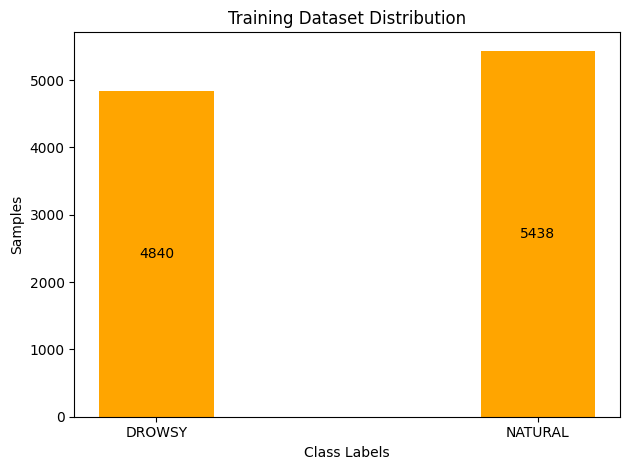

In [14]:
bar = plt.bar(x=class_names, height=class_samples, width=0.3, color='orange')
plt.bar_label(bar, label_type='center')
plt.xlabel('Class Labels')
plt.ylabel('Samples')
plt.title('Training Dataset Distribution')
plt.tight_layout()
plt.savefig('train_distribution.png')    
plt.show()

### Data Preprocessing & Augmentation

*Displaying Random Training Images Dimension*

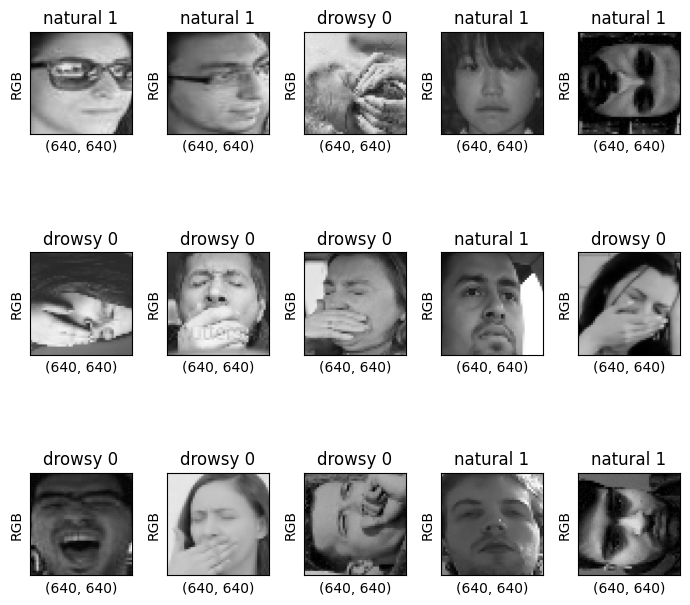

In [34]:
fig = plt.figure(figsize=(7, 7))
rows, columns = 3, 5

for i in range(1, rows*columns+1):
    fig.add_subplot(rows, columns, i)

    # random numbers -> tuple to int -> return one
    random_idx = torch.randint(0, len(train_data), size=(1, )).item()
    data, target = train_data[random_idx]
    
    plt.imshow(data)
    plt.title(f'{class_names[target].lower()} {target}')
    plt.ylabel(data.mode)
    plt.xlabel(data.size)
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

> *First Compute Mean, Std Deviation of Train Image Pixels Using Sum & Square Method*

In [9]:
# train_stats_transform = T.Compose([
#     T.Resize((224, 224)),
#     T.ToTensor()
# ])

In [ ]:
# train_stats_loader = DataLoader(ImageFolder(root=train_data.root, transform=train_stats_transform), 
#                               batch_size=64, num_workers=4, 
#                               pin_memory=(device.type == 'cuda'), shuffle=False)

*Using Sum and Square Method instead of Batch Averaging Method*

In [10]:
# # three tensors (R, G, B)
# channel_sum = torch.zeros(3, device=device)
# channel_sum_sq = torch.zeros(3, device=device)

# # total pixels
# pixels = 0

# # shape [0,1,2,3] -> [batch, channel, height, width]
# for img, lbl in train_stats_loader:
#     img = img.to(device, non_blocking=True)

#     # [R, G, B] -> one pixel
#     channel_sum += torch.sum(img, dim=[0,2,3])
#     channel_sum_sq += torch.sum(img**2, dim=[0,2,3])

#     # batch * height * width
#     pixels += img.shape[0] * img.shape[2] * img.shape[3]
#     # alternative len(train_data)*224*224

# # Average brightness
# mean, meansq = channel_sum / pixels, channel_sum_sq / pixels

# # How pixels spread or far from mean
# variance = meansq - mean**2
# std = torch.sqrt(variance.clamp_min(0))

# print(f'Training Data Mean: {mean}, Std: {std}')

In [36]:
# len(train_data)/ 64

num_batches = 161

*Computed mean and std*

In [37]:
mean = [0.4373, 0.4373, 0.4373]
std = [0.2449, 0.2449, 0.2449]

> *Training Random Geometric and Appearance Transformation & Augmentation*

***Experiment No.1***

In [38]:
train_transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomApply(torch.nn.ModuleList([
        T.RandomHorizontalFlip(),
        T.RandomAdjustSharpness(sharpness_factor=2),
        T.RandomAutocontrast(),
        T.RandomEqualize(p=0.3),
    ]), p=0.5),
    T.ColorJitter(brightness=0.5, contrast=0.5, saturation=0.5),
    T.RandomRotation(degrees=(0,90)),
    T.ToTensor(),
    T.Normalize(mean, std)
])

In [39]:
train_loader = DataLoader(ImageFolder(root=train_data.root, transform=train_transform), batch_size=64, num_workers=4, pin_memory=(device.type == 'cuda'), shuffle=True)
size = train_loader.dataset
print(size)

Dataset ImageFolder
    Number of datapoints: 10278
    Root location: /kaggle/input/datasets/mirzaabubakarmughal/driver-fatigue-classification/train
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               RandomApply(
               p=0.5
               RandomHorizontalFlip(p=0.5)
               RandomAdjustSharpness(sharpness_factor=2,p=0.5)
               RandomAutocontrast(p=0.5)
               RandomEqualize(p=0.3)
           )
               ColorJitter(brightness=(0.5, 1.5), contrast=(0.5, 1.5), saturation=(0.5, 1.5), hue=None)
               RandomRotation(degrees=[0.0, 90.0], interpolation=nearest, expand=False, fill=0)
               ToTensor()
               Normalize(mean=[0.4373, 0.4373, 0.4373], std=[0.2449, 0.2449, 0.2449])
           )


### Model Architecture Design

*CNN From Scratch*

In [29]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        
    def foward(input, self):
        return output

model = CNN().to(device)
print(model)

CNN()


*Hyperparameters*

In [ ]:
epochs = 20
batch_size = 64
criterion = nn.BCEWithLogitsLoss(reduction='None')
optimizer = optim.Adam(model.parameters(), lr=0.001)

### Model Training Pipeline

*Training Loop*

In [ ]:
for epoch in range(epochs): 
    print(f'Epoch [{epoch+1}/{epochs}]') 
    
    run_loss = 0.0 
    correct = 0
    total = 0

    # train mode for batch normalize and dropout layers
    model.train() 
    
    for batch, (images, labels) in enumerate(train_loader): 
        images = images.to(device, non_blocking=True) 
        labels = labels.to(device, non_blocking=True).type(torch.float)
        
        # Forward pass
        outputs = model(images).reshape(-1)
        labels = labels.reshape(-1)
        loss = criterion(outputs, labels) 

        # Backward pass
        optimizer.zero_grad()
        loss.backward() 
        optimizer.step() 
        
        # Running Accuracy
        predictions = (outputs >= 0.0).float()
        batch_correct = (predictions == labels).sum().item()
        run_accuracy = batch_correct / labels.size(0)
        
        # Averaging
        run_loss += loss.item()
        correct += batch_correct
        total += labels.size(0)

        # Current Batch
        current = batch * batch_size + len(images) 

        # Each batch performance
        print(f'Loss: {loss.item():.4f}  Accuracy: {run_accuracy:.4f}  Batch: [{current:>5d}/{size:>5d}]') 

    # Entire Performance
    avg_loss = run_loss / num_batches
    avg_accuracy = (correct/total) * 100
    
    print(f'Training Average Accuracy: {(avg_accuracy):>0.1f}%  Training Average Loss: {avg_loss:>8f}\n')
print("Done!")

### Evaluation & Hyperparameter Tunning

In [14]:
# valid_transform = T.Compose([
#     T.Resize((224, 224))
#     T.ToTensor(),
#     T.Normalize(mean, std)
# ])

In [15]:
# valid_loader = DataLoader(ImageFolder(root=train_data.root, transform=valid_transform), 
#                          batch_size=64, num_workers=4, pin_memory=(device.type == 'cuda'), shuffle=False))

### Model Inference Pipeline

In [16]:
# test_transform = T.Compose([
#     T.Resize((224, 224))
#     T.ToTensor(),
#     T.Normalize(mean, std)
# ])

In [17]:
# test_loader = DataLoader(ImageFolder(root=train_data.root, transform=test_transform), 
#                          batch_size=64, num_workers=4, pin_memory=(device.type == 'cuda'), shuffle=False))

### Model Deployment MLOps